# AIM Score × SUS por página

AIM Score do WAVE e SUS médio de cada página, por grupo; entre parênteses, as violações detectadas pelo axe.

In [4]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


DADOS = Path("../dados")

# Verifica se as planilhas estão na pasta dados/ (ao lado da pasta notebooks/)
if not DADOS.exists():
    raise FileNotFoundError(f"Pasta de dados não encontrada: {DADOS.resolve()}. Crie a pasta dados/ ao lado de notebooks/ e coloque nela as planilhas.")

FIGURAS = Path("../figuras")
FIGURAS.mkdir(exist_ok=True)  # cria a pasta das figuras, se não existir


## SUS médio de cada página

In [5]:
aval = pd.read_excel(DADOS / "Questionario_avaliacao_landing_page_usuario_final_respostas.xlsx")
aval.columns = [c.strip() for c in aval.columns]

G1 = {1, 3, 4, 6, 7, 9, 12, 18}
num = lambda s: pd.to_numeric(s.astype(str).str.extract(r"(\d)")[0], errors="coerce")
sus = aval.iloc[:, 16:26].apply(num)
av = pd.DataFrame({"site": aval.iloc[:, 2].astype(int),
                   "sus": ((sus.iloc[:, 0::2] - 1).sum(axis=1) + (5 - sus.iloc[:, 1::2]).sum(axis=1)) * 2.5})
av.groupby("site").sus.mean().round(1).rename("SUS médio")

site
1     87.5
2     86.7
3     75.0
4     77.5
5     87.5
6     84.2
7     87.5
8     79.2
9     75.8
10    88.3
12    88.3
13    67.5
14    85.0
18    66.7
19    86.7
20    67.5
Name: SUS médio, dtype: float64

## Figura

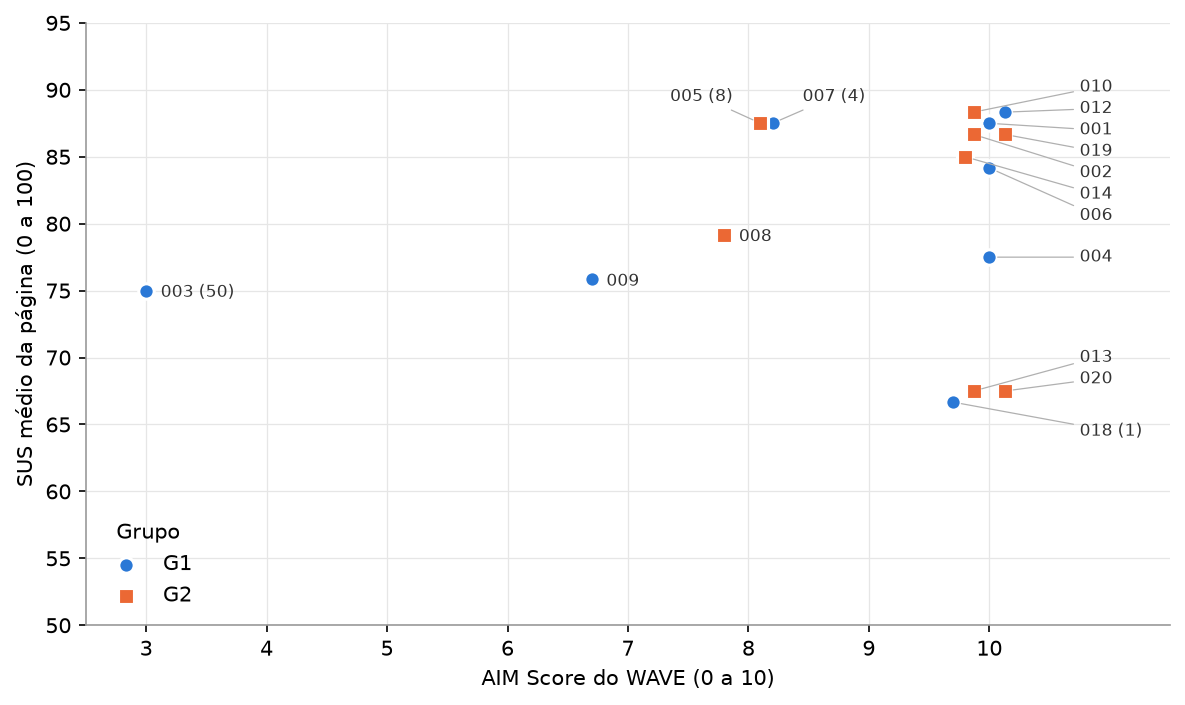

In [6]:
aim = {1: 10, 3: 3.0, 4: 10, 6: 10, 7: 8.2, 9: 6.7, 12: 10, 18: 9.7,
       2: 10, 5: 8.1, 8: 7.8, 10: 10, 13: 10, 14: 9.8, 19: 10, 20: 10}
axe = {3: 50, 7: 4, 18: 1, 5: 8}
d = pd.DataFrame({"aim": pd.Series(aim), "sus": av.groupby("site").sus.mean()})
d["g"] = ["G1" if i in G1 else "G2" for i in d.index]

# Páginas com AIM 10 e SUS iguais são deslocadas na horizontal para não se sobreporem
dx = {10: -0.13, 12: 0.13, 2: -0.13, 19: 0.13, 13: -0.13, 20: 0.13}
lab = {10: (10.75, 90.2), 12: (10.75, 88.6), 1: (10.75, 87.0), 19: (10.75, 85.4), 2: (10.75, 83.8),
       14: (10.75, 82.2), 6: (10.75, 80.6), 4: (10.75, 77.5), 13: (10.75, 70.0), 20: (10.75, 68.4),
       18: (10.75, 64.5), 5: (7.35, 89.5), 7: (8.45, 89.5)}

plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
fig, ax = plt.subplots(figsize=(8, 4.8), dpi=150)
sty = {"G1": dict(c="#2a78d6", m="o"), "G2": dict(c="#eb6834", m="s")}
for g in ["G1", "G2"]:
    sub = d[d.g == g]
    ax.scatter(sub.aim + [dx.get(i, 0) for i in sub.index], sub.sus, s=55, marker=sty[g]["m"],
               color=sty[g]["c"], edgecolor="white", linewidth=1.5, zorder=3, label=g)
for i, r in d.iterrows():
    t = f"{i:03d}" + (f" ({axe[i]})" if i in axe else "")
    x = r.aim + dx.get(i, 0)
    if i not in lab:
        ax.annotate(t, (x, r.sus), xytext=(7, -3), textcoords="offset points", fontsize=8, color="#333333")
    else:
        ax.annotate(t, (x, r.sus), xytext=lab[i], textcoords="data", fontsize=8, color="#333333", va="center",
                    arrowprops=dict(arrowstyle="-", color="#b0b0b0", lw=0.6, shrinkA=1, shrinkB=4))
ax.set_xlabel("AIM Score do WAVE (0 a 10)")
ax.set_ylabel("SUS médio da página (0 a 100)")
ax.set_xlim(2.5, 11.5); ax.set_ylim(50, 95); ax.set_xticks(range(3, 11))
ax.grid(color="#e6e6e6", linewidth=0.6, zorder=0); ax.set_axisbelow(True)
for sp in ["top", "right"]:
    ax.spines[sp].set_visible(False)
for sp in ["left", "bottom"]:
    ax.spines[sp].set_color("#999999")
ax.legend(title="Grupo", frameon=False, loc="lower left")
fig.tight_layout()
fig.savefig("../figuras/fig_tecnica_sus.png", dpi=300)
plt.show()